# SPÉ 1 Mon exploration des données

Dans ce notebook, j'analyse les métadonnées du projet pour comprendre ce que le sous-échantillon conserve. Je regarde surtout la présence des petites lésions, le poids des patientes et les informations disponibles pour déterminer le stade pN.

Mes calculs portent sur H0, H1, H3 et H4. H2 reste réservé au test final. Cette partie contient une exploration des données, sans entraînement de modèle ni score de classification.

Le notebook fonctionne sur CPU avec les trois fichiers du dossier `data`. Les figures et les tableaux sont enregistrés dans `exploration_complementaire`.


## 0. Préparation

En local, placer ce notebook à la racine du dépôt et utiliser les dépendances du projet. Sur Colab, lancer les cellules dans l'ordre. Si les données sont absentes, seuls les trois petits fichiers de métadonnées sont téléchargés depuis la version du dépôt utilisée pour ce travail.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display, Markdown

SEED = 42
CENTRES = [0, 1, 3, 4]
BASE_COMMIT = "33da9766857e51de006af6d1442739011a718dad"
EXPORTER = True
FICHIERS = ["metadata_complete.zip", "ids_sous_echantillon.csv", "stages.csv"]

candidats = [Path("data"), Path("donnees"), Path("."), Path("../data")]
DATA = next((p for p in candidats if all((p / f).exists() for f in FICHIERS)), None)
if DATA is None:
    if "google.colab" not in sys.modules:
        raise FileNotFoundError("Placer les trois fichiers dans data puis relancer le notebook.")
    DATA = Path("data")
    DATA.mkdir(exist_ok=True)
    base_url = f"https://raw.githubusercontent.com/Cloud-io09/model-cancer-sein/{BASE_COMMIT}/data"
    for nom in FICHIERS:
        urllib.request.urlretrieve(f"{base_url}/{nom}", DATA / nom)

SORTIE = Path("exploration_complementaire")
if EXPORTER:
    (SORTIE / "figures").mkdir(parents=True, exist_ok=True)
    (SORTIE / "tableaux").mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.grid": False,
    "figure.facecolor": "white", "axes.facecolor": "white"
})
BLEU, ORANGE, ROUGE, GRIS = "#31688e", "#e69f00", "#bc3754", "#b8c1cc"
TABLEAUX = {}

def tableau(nom, df):
    TABLEAUX[nom] = df.copy()
    display(df.round(4))
    if EXPORTER:
        df.to_csv(SORTIE / "tableaux" / f"{nom}.csv", index=False, encoding="utf-8-sig")

def figure(nom, fig):
    fig.tight_layout()
    if EXPORTER:
        fig.savefig(SORTIE / "figures" / f"{nom}.png", bbox_inches="tight")
    plt.show()
    plt.close(fig)

def nombre(n):
    return f"{n:,}".replace(",", " ")


## 1. Vérifier les fichiers et les jointures

Je commence par vérifier les identifiants et les correspondances entre les fichiers. Une ligne de métadonnées correspond à un patch. `stages.csv` contient deux niveaux différents, les lames en `.tif` et les patientes en `.zip`.

Les données Camelyon17-WILDS permettent d'étudier les écarts entre hôpitaux. Ce cadre est présenté par [Koh et al. (2021)](https://proceedings.mlr.press/v139/koh21a.html).

Je filtre H2 avant de conserver les lignes pour l'analyse. Les contrôles ci-dessous portent donc sur le développement. Les jointures utilisent les identifiants, jamais la position des lignes.


In [2]:
morceaux = []
n_total, n_reserve = 0, 0
with zipfile.ZipFile(DATA / "metadata_complete.zip") as z:
    with z.open("metadata_complete.csv") as f:
        for bloc in pd.read_csv(f, chunksize=100_000):
            n_total += len(bloc)
            n_reserve += int(bloc.center.eq(2).sum())
            morceaux.append(bloc.loc[bloc.center.isin(CENTRES)].copy())
meta = pd.concat(morceaux, ignore_index=True).sort_values("image_id").reset_index(drop=True)
del morceaux, bloc

ids = pd.read_csv(DATA / "ids_sous_echantillon.csv")
ids_dev = ids.loc[ids.split.ne("test")].copy()
stages = pd.read_csv(DATA / "stages.csv")
stages = stages.loc[stages.center.isin(CENTRES)].copy()

lames_off = stages.loc[stages.patient.str.endswith(".tif")].copy()
lames_off = lames_off.rename(columns={"patient": "nom_lame", "stage": "classe_lame"})
lames_off["patient"] = lames_off.nom_lame.str.extract(r"patient_(\d+)")[0].astype(int)
lames_off["node"] = lames_off.nom_lame.str.extract(r"node_(\d+)")[0].astype(int)
pat_off = stages.loc[stages.patient.str.endswith(".zip")].copy()
pat_off["patient"] = pat_off.patient.str.extract(r"patient_(\d+)")[0].astype(int)
pat_off = pat_off.rename(columns={"stage": "pn_officiel"})

ech = ids_dev.merge(meta, on="image_id", how="left", suffixes=("_demande", ""),
                    validate="one_to_one", indicator=True)
controles = {
    "Identifiants absents du sous-échantillon": int(ech._merge.ne("both").sum()),
    "Doublons d'identifiants dans les métadonnées": int(meta.image_id.duplicated().sum()),
    "Doublons d'identifiants demandés": int(ids_dev.image_id.duplicated().sum()),
    "Valeurs manquantes dans les métadonnées": int(meta.isna().sum().sum()),
    "Valeurs manquantes dans les identifiants": int(ids_dev.isna().sum().sum()),
    "Valeurs manquantes dans les stades": int(stages.isna().sum().sum()),
    "Splits incohérents entre les fichiers": int(ech.split_demande.ne(ech.split).sum()),
    "Positions répétées dans une même lame": int(meta.duplicated(["slide", "x_coord", "y_coord"]).sum()),
    "Lames associées à plusieurs patientes, ganglions ou centres": int(
        meta.groupby("slide")[["patient", "node", "center"]].nunique().gt(1).any(axis=1).sum()),
    "Patientes associées à plusieurs centres": int(meta.groupby("patient").center.nunique().gt(1).sum()),
    "Doublons de lames officielles": int(lames_off.duplicated(["patient", "node"]).sum()),
    "Doublons de patientes officielles": int(pat_off.patient.duplicated().sum()),
    "Patientes sans exactement cinq lames officielles": int(lames_off.groupby("patient").size().ne(5).sum()),
    "Classes de patch inattendues": int((~meta.label.isin([0, 1])).sum()),
    "Classes de lame inattendues": int((~lames_off.classe_lame.isin(["negative", "itc", "micro", "macro"])).sum()),
    "Lignes H2 conservées": int(meta.center.eq(2).sum())
}
assert not any(controles.values()), controles
ech = ech.drop(columns=["split_demande", "_merge"]).sort_values("image_id").reset_index(drop=True)

meta = meta.merge(lames_off[["patient", "node", "center", "nom_lame", "classe_lame"]],
                  on=["patient", "node", "center"], how="left", validate="many_to_one")
ech = ech.merge(lames_off[["patient", "node", "center", "nom_lame", "classe_lame"]],
                on=["patient", "node", "center"], how="left", validate="many_to_one")
controles["Patchs sans classe officielle de lame"] = int(meta.classe_lame.isna().sum())
assert controles["Patchs sans classe officielle de lame"] == 0
tableau("01_controles", pd.DataFrame(controles.items(), columns=["controle", "anomalies"]))
print(f"Fichier complet {nombre(n_total)} patchs. H2 réservé {nombre(n_reserve)} patchs.")
print(f"Analyse de développement {nombre(len(meta))} patchs et {nombre(len(ech))} retenus.")


,controle,anomalies
0,Identifiants absents du sous-échantillon,0
1,Doublons d'identifiants dans les métadonnées,0
2,Doublons d'identifiants demandés,0
3,Valeurs manquantes dans les métadonnées,0
4,Valeurs manquantes dans les identifiants,0
5,Valeurs manquantes dans les stades,0
6,Splits incohérents entre les fichiers,0
7,Positions répétées dans une même lame,0
8,"Lames associées à plusieurs patientes, ganglio...",0
9,Patientes associées à plusieurs centres,0


Fichier complet 455 954 patchs. H2 réservé 85 054 patchs.
Analyse de développement 370 900 patchs et 31 000 retenus.


In [3]:
perimetre = pd.DataFrame([
    {"ensemble": nom, "patchs": len(d), "patientes": d.patient.nunique(),
     "lames": d.slide.nunique(), "centres": d.center.nunique(),
     "positifs": int(d.label.sum())}
    for nom, d in [("Métadonnées hors H2", meta), ("Sous-échantillon hors H2", ech)]
])
tableau("02_perimetre", perimetre)

partages = []
for a, b in combinations(["train", "id_val", "val_ood"], 2):
    da, db = ech.loc[ech.split.eq(a)], ech.loc[ech.split.eq(b)]
    partages.append({"ensemble_a": a, "ensemble_b": b,
        "patchs_communs": len(set(da.image_id) & set(db.image_id)),
        "lames_communes": len(set(da.slide) & set(db.slide)),
        "patientes_communes": len(set(da.patient) & set(db.patient))})
tableau("03_groupes_partages", pd.DataFrame(partages))


,ensemble,patchs,patientes,lames,centres,positifs
0,Métadonnées hors H2,370900,34,40,4,185450
1,Sous-échantillon hors H2,31000,34,40,4,15500


,ensemble_a,ensemble_b,patchs_communs,lames_communes,patientes_communes
0,train,id_val,0,30,26
1,train,val_ood,0,0,0
2,id_val,val_ood,0,0,0


`train` et `id_val` partagent des patientes et des lames. Le notebook du groupe traite déjà ce point en créant `val_lames` par patiente. Le tableau précédent sert de contrôle. Il ne remet pas en cause le découpage corrigé du groupe.


## 2. Ce que change le sous-échantillon

Je compare chaque lame avant et après la sélection. Le taux de conservation est le nombre de patchs retenus divisé par le nombre de patchs disponibles. Une lame peut être conservée tout en perdant certains types de patchs.


,slide,patient,node,center,classe_lame,patchs_complets,positifs_complets,patchs_retenus,positifs_retenus,conservation_pct,conservation_positifs_pct,poids_complet_pct,poids_retenu_pct,ecart_poids_points
0,0,4,4,0,itc,4316,36,683,5,15.8248,13.8889,1.1637,2.2032,1.0396
1,1,9,1,0,micro,4597,307,692,57,15.0533,18.5668,1.2394,2.2323,0.9928
2,2,10,4,0,micro,4046,1192,602,191,14.8789,16.0235,1.0909,1.9419,0.8511
3,3,12,0,0,macro,13637,12649,2059,1896,15.0986,14.9893,3.6767,6.6419,2.9652
4,4,15,1,0,macro,7294,4885,1089,750,14.9301,15.3531,1.9666,3.5129,1.5463
5,5,15,2,0,macro,3260,1178,512,190,15.7055,16.1290,0.8789,1.6516,0.7727
6,6,16,1,0,itc,3427,5,496,1,14.4733,20.0000,0.9240,1.6000,0.6760
7,7,17,1,0,itc,1596,7,252,1,15.7895,14.2857,0.4303,0.8129,0.3826
8,8,17,2,0,macro,13455,8704,2024,1295,15.0427,14.8782,3.6277,6.5290,2.9014
9,9,17,4,0,micro,3808,755,591,114,15.5200,15.0993,1.0267,1.9065,0.8798


,center,patchs_complets,patchs_retenus,conservation_pct,poids_complet_pct,poids_retenu_pct
0,0,59436,9000,15.1423,16.0248,29.0323
1,1,34904,4000,11.4600,9.4106,12.9032
2,3,129838,9000,6.9317,35.0062,29.0323
3,4,146722,9000,6.1340,39.5584,29.0323


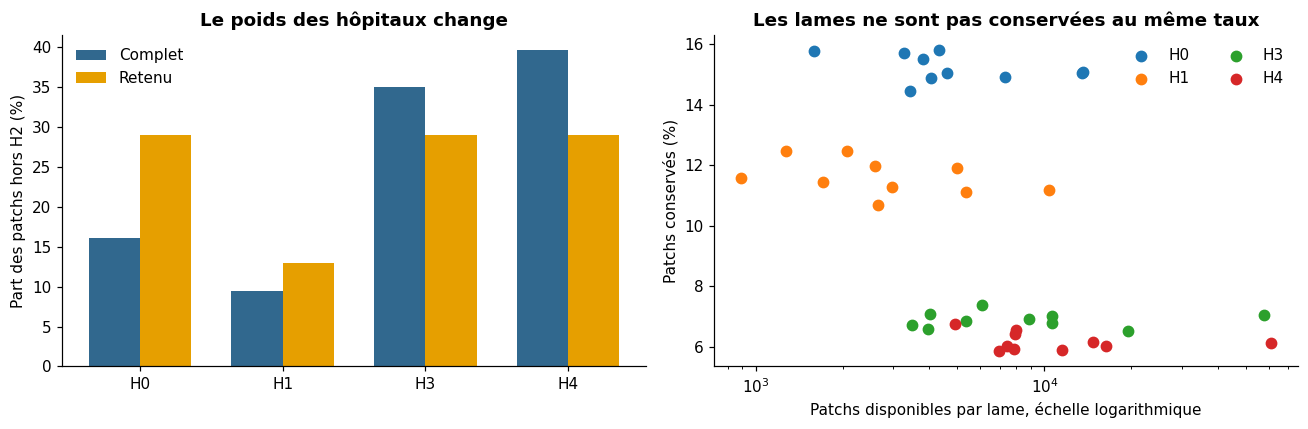

In [4]:
def resume_lames(d):
    return d.groupby(["slide", "patient", "node", "center", "classe_lame"], as_index=False).agg(
        patchs=("label", "size"), positifs=("label", "sum"))

lames = resume_lames(meta).merge(resume_lames(ech),
    on=["slide", "patient", "node", "center", "classe_lame"], how="left",
    suffixes=("_complets", "_retenus"), validate="one_to_one")
lames[["patchs_retenus", "positifs_retenus"]] = lames[["patchs_retenus", "positifs_retenus"]].fillna(0).astype(int)
lames["conservation_pct"] = 100 * lames.patchs_retenus / lames.patchs_complets
lames["conservation_positifs_pct"] = 100 * lames.positifs_retenus / lames.positifs_complets
lames["poids_complet_pct"] = 100 * lames.patchs_complets / len(meta)
lames["poids_retenu_pct"] = 100 * lames.patchs_retenus / len(ech)
lames["ecart_poids_points"] = lames.poids_retenu_pct - lames.poids_complet_pct
tableau("04_comparaison_lames", lames)

centres = meta.groupby("center").size().to_frame("patchs_complets").join(
    ech.groupby("center").size().rename("patchs_retenus"))
centres["conservation_pct"] = 100 * centres.patchs_retenus / centres.patchs_complets
centres["poids_complet_pct"] = 100 * centres.patchs_complets / len(meta)
centres["poids_retenu_pct"] = 100 * centres.patchs_retenus / len(ech)
tableau("05_comparaison_centres", centres.reset_index())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(centres))
axes[0].bar(x - .18, centres.poids_complet_pct, .36, label="Complet", color=BLEU)
axes[0].bar(x + .18, centres.poids_retenu_pct, .36, label="Retenu", color=ORANGE)
axes[0].set_xticks(x, [f"H{h}" for h in centres.index])
axes[0].set_ylabel("Part des patchs hors H2 (%)")
axes[0].set_title("Le poids des hôpitaux change")
axes[0].legend(frameon=False)
for h in CENTRES:
    g = lames.loc[lames.center.eq(h)]
    axes[1].scatter(g.patchs_complets, g.conservation_pct, label=f"H{h}", s=45)
axes[1].set_xscale("log")
axes[1].set_xlabel("Patchs disponibles par lame, échelle logarithmique")
axes[1].set_ylabel("Patchs conservés (%)")
axes[1].set_title("Les lames ne sont pas conservées au même taux")
axes[1].legend(frameon=False, ncol=2)
figure("01_representativite", fig)


Le rééquilibrage des hôpitaux est prévu par le pack. Ce n'est pas une erreur. En revanche, les statistiques calculées sur le sous-échantillon décrivent cette sélection particulière.


## 3. Les petites lésions restent rares

Je distingue le label du patch et la classe de sa lame. Le label vaut 0 ou 1. Les classes `itc`, `micro` et `macro` décrivent la lame d'origine. Un patch normal peut donc venir d'une lame atteinte.

Le cadre CAMELYON17 et le passage des lames au statut de la patiente sont présentés par [Bándi et al. (2019)](https://doi.org/10.1109/TMI.2018.2867350). Les effectifs affichés ici viennent de mes calculs sur les fichiers du projet.


,classe_lame,lames,patchs_complets,positifs_complets,patchs_retenus,positifs_retenus,part_positifs_retenus_pct
0,itc,14,86520,484,6611,31,0.2000
1,micro,13,48130,4455,4775,586,3.7806
2,macro,13,236250,180511,19614,14883,96.0194


,split,classe_lame,patchs,positifs,lames
0,id_val,itc,706,2,12
1,id_val,macro,1884,1453,10
2,id_val,micro,410,45,8
3,train,itc,5467,26,12
4,train,macro,15375,11595,10
5,train,micro,3158,379,8
6,val_ood,itc,438,3,2
7,val_ood,macro,2355,1835,3
8,val_ood,micro,1207,162,5


,slide,patient,node,center,classe_lame,positifs_complets,positifs_retenus,patchs_retenus
20,30,60,3,3,itc,15,0,720
23,33,64,0,3,itc,19,0,285
26,36,68,1,3,itc,16,0,748


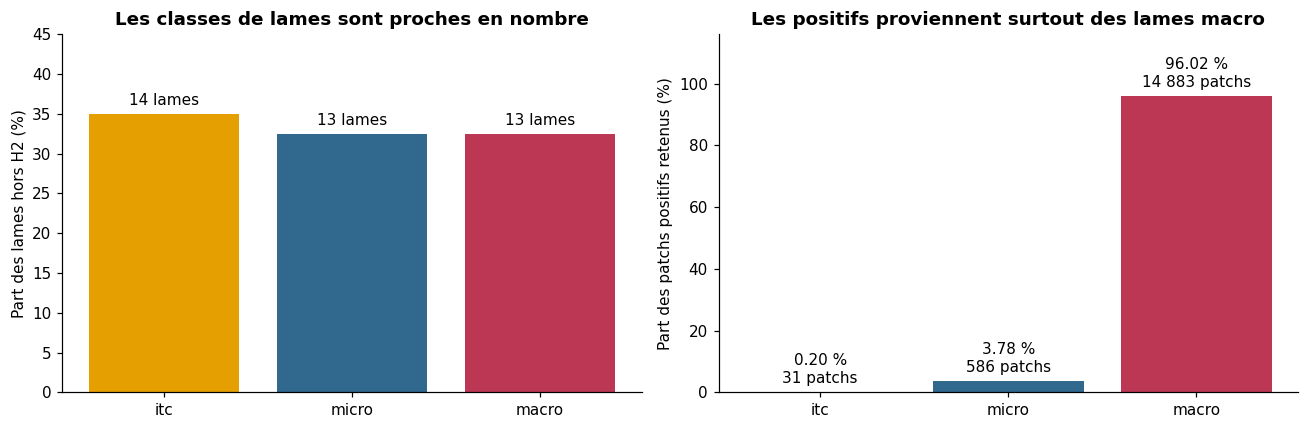

14 883 positifs sur 15 500 viennent de lames macro.
H1 contient 3 patchs positifs issus de lames itc.
Le rappel sur ce petit groupe changerait de 33.3 points pour un seul patch.


In [5]:
ORDRE_CLASSES = ["itc", "micro", "macro"]
types = lames.groupby("classe_lame").agg(
    lames=("slide", "size"), patchs_complets=("patchs_complets", "sum"),
    positifs_complets=("positifs_complets", "sum"), patchs_retenus=("patchs_retenus", "sum"),
    positifs_retenus=("positifs_retenus", "sum")).reindex(ORDRE_CLASSES)
types["part_positifs_retenus_pct"] = 100 * types.positifs_retenus / types.positifs_retenus.sum()
tableau("06_types_lesions", types.reset_index())

par_split = ech.groupby(["split", "classe_lame"], as_index=False).agg(
    patchs=("label", "size"), positifs=("label", "sum"), lames=("slide", "nunique"))
tableau("07_lesions_par_split", par_split)

perdues = lames.loc[lames.positifs_complets.gt(0) & lames.positifs_retenus.eq(0),
    ["slide", "patient", "node", "center", "classe_lame", "positifs_complets", "positifs_retenus", "patchs_retenus"]]
tableau("08_lames_sans_positif_retenu", perdues)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
parts = 100 * types.lames / types.lames.sum()
bars = axes[0].bar(ORDRE_CLASSES, parts, color=[ORANGE, BLEU, ROUGE])
axes[0].bar_label(bars, labels=[f"{n} lames" for n in types.lames], padding=4)
axes[0].set_ylim(0, 45)
axes[0].set_ylabel("Part des lames hors H2 (%)")
axes[0].set_title("Les classes de lames sont proches en nombre")
bars = axes[1].bar(ORDRE_CLASSES, types.part_positifs_retenus_pct, color=[ORANGE, BLEU, ROUGE])
axes[1].bar_label(bars, labels=[f"{v:.2f} %\n{nombre(int(n))} patchs" for v, n in
    zip(types.part_positifs_retenus_pct, types.positifs_retenus)], padding=4)
axes[1].set_ylim(0, 116)
axes[1].set_ylabel("Part des patchs positifs retenus (%)")
axes[1].set_title("Les positifs proviennent surtout des lames macro")
figure("02_petites_lesions", fig)

itc_h1 = ech.loc[ech.center.eq(1) & ech.classe_lame.eq("itc")]
n_itc_h1 = int(itc_h1.label.sum())
print(f"{nombre(int(types.loc['macro', 'positifs_retenus']))} positifs sur {nombre(int(ech.label.sum()))} viennent de lames macro.")
print(f"H1 contient {n_itc_h1} patchs positifs issus de lames itc.")
if n_itc_h1:
    print(f"Le rappel sur ce petit groupe changerait de {100 / n_itc_h1:.1f} points pour un seul patch.")


Les effectifs expliquent pourquoi un score global ne suffit pas à décrire les petites lésions. Il faudrait regarder les performances par classe de lame avec leurs effectifs. Ici, aucun rappel n'est mesuré. Les patchs d'une même lame ne sont pas des cas indépendants.

Les lames présentes sont toutes positives dans les annotations officielles. Des patchs normaux issus de ces lames ne permettent pas d'estimer la spécificité sur des lames entièrement négatives.


## 4. Le poids des patientes

Une patiente qui fournit beaucoup de patchs pèse davantage dans une moyenne globale. Je mesure cette concentration et je compare trois façons de calculer une proportion positive.


,patient,center,patchs_complets,positifs_complets,patchs_retenus,positifs_retenus,poids_retenu_pct
0,73,3,57375,48130,4057,3392,13.0871
1,96,4,61110,56666,3747,3489,12.0871
2,17,0,18859,9466,2867,1410,9.2484
3,12,0,13637,12649,2059,1896,6.6419
4,15,0,10554,6063,1601,940,5.1645
5,75,3,19485,14031,1270,910,4.0968
6,22,1,10404,8776,1165,986,3.7581
7,99,4,16354,10045,985,608,3.1774
8,86,4,15806,18,977,2,3.1516
9,92,4,14703,5949,906,353,2.9226


,ensemble,patientes_les_plus_representees,patchs,part_pct
0,Complet,1,61110,16.4761
1,Complet,2,118485,31.9453
2,Complet,5,173183,46.6926
3,Complet,10,239516,64.5770
4,Retenu,1,4057,13.0871
5,Retenu,2,7804,25.1742
6,Retenu,5,14331,46.2290
7,Retenu,10,19634,63.3355


,ensemble,meme_poids_par,part_positive_pct
0,Complet,Patch,50.0000
1,Complet,Lame,25.2018
2,Complet,Patiente,26.5247
3,Retenu,Patch,50.0000
4,Retenu,Lame,25.4683
5,Retenu,Patiente,26.7375


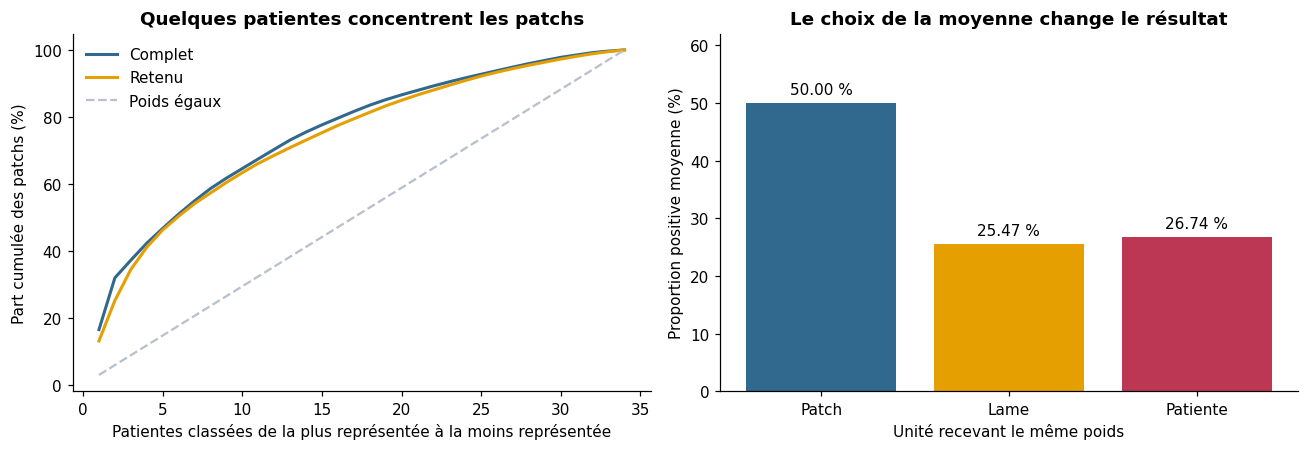

In [6]:
patientes = meta.groupby("patient").agg(center=("center", "first"),
    patchs_complets=("label", "size"), positifs_complets=("label", "sum"))
patientes = patientes.join(ech.groupby("patient").agg(
    patchs_retenus=("label", "size"), positifs_retenus=("label", "sum")))
patientes["poids_retenu_pct"] = 100 * patientes.patchs_retenus / len(ech)
patientes = patientes.sort_values("patchs_retenus", ascending=False)
tableau("09_poids_patientes", patientes.reset_index())

concentration = []
for nom, col in [("Complet", "patchs_complets"), ("Retenu", "patchs_retenus")]:
    valeurs = patientes[col].sort_values(ascending=False)
    for k in [1, 2, 5, 10]:
        concentration.append({"ensemble": nom, "patientes_les_plus_representees": k,
            "patchs": int(valeurs.head(k).sum()), "part_pct": 100 * valeurs.head(k).sum() / valeurs.sum()})
tableau("10_concentration", pd.DataFrame(concentration))

moyennes = []
for nom, d in [("Complet", meta), ("Retenu", ech)]:
    for unite, valeur in [("Patch", d.label.mean()),
        ("Lame", d.groupby("slide").label.mean().mean()),
        ("Patiente", d.groupby("patient").label.mean().mean())]:
        moyennes.append({"ensemble": nom, "meme_poids_par": unite, "part_positive_pct": 100 * valeur})
moyennes = pd.DataFrame(moyennes)
tableau("11_unite_de_moyenne", moyennes)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for nom, col, couleur in [("Complet", "patchs_complets", BLEU), ("Retenu", "patchs_retenus", ORANGE)]:
    v = patientes[col].sort_values(ascending=False)
    axes[0].plot(np.arange(1, len(v) + 1), 100 * v.cumsum() / v.sum(), label=nom, color=couleur, lw=2)
axes[0].plot([1, len(patientes)], [100 / len(patientes), 100], color=GRIS, ls="--", label="Poids égaux")
axes[0].set_xlabel("Patientes classées de la plus représentée à la moins représentée")
axes[0].set_ylabel("Part cumulée des patchs (%)")
axes[0].set_title("Quelques patientes concentrent les patchs")
axes[0].legend(frameon=False)
m = moyennes.loc[moyennes.ensemble.eq("Retenu")]
bars = axes[1].bar(m.meme_poids_par, m.part_positive_pct, color=[BLEU, ORANGE, ROUGE])
axes[1].bar_label(bars, labels=[f"{v:.2f} %" for v in m.part_positive_pct], padding=4)
axes[1].set_ylim(0, 62)
axes[1].set_xlabel("Unité recevant le même poids")
axes[1].set_ylabel("Proportion positive moyenne (%)")
axes[1].set_title("Le choix de la moyenne change le résultat")
figure("03_poids_patientes", fig)


Les trois moyennes répondent à des questions différentes. La moyenne par lame ou par patiente ne corrige pas automatiquement le jeu de données. Aucune de ces valeurs n'est une estimation de la prévalence clinique.


## 5. Voir la perte d'information sur une lame

La carte compare les positions disponibles et les positions retenues sur la première lame ayant perdu tous ses positifs, selon son identifiant. Ce choix illustre le cas observé. Il ne représente pas toutes les lames.

Les coordonnées restent dans l'unité du CSV. Un espace vide signifie qu'aucun patch n'est présent à cet endroit dans le fichier affiché. Il ne prouve pas l'absence de tissu ni de tumeur.


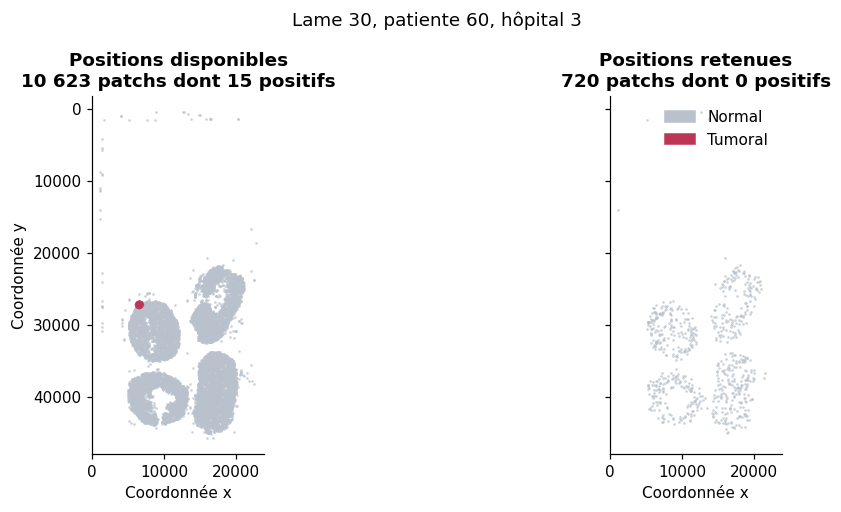

In [7]:
if len(perdues):
    slide_exemple = int(perdues.slide.min())
else:
    slide_exemple = int(lames.sort_values("conservation_positifs_pct").slide.iloc[0])
a = meta.loc[meta.slide.eq(slide_exemple)]
b = ech.loc[ech.slide.eq(slide_exemple)]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7), sharex=True, sharey=True)
for ax, d, titre in zip(axes, [a, b], ["Positions disponibles", "Positions retenues"]):
    for label, couleur, taille in [(0, GRIS, 3), (1, ROUGE, 24)]:
        g = d.loc[d.label.eq(label)]
        ax.scatter(g.x_coord, g.y_coord, s=taille, c=couleur, alpha=.7, linewidths=0)
    ax.set_title(f"{titre}\n{nombre(len(d))} patchs dont {int(d.label.sum())} positifs")
    ax.set_xlabel("Coordonnée x")
    ax.set_aspect("equal", adjustable="box")
axes[0].set_ylabel("Coordonnée y")
axes[0].invert_yaxis()
axes[1].legend(handles=[Patch(color=GRIS, label="Normal"), Patch(color=ROUGE, label="Tumoral")],
    frameon=False, loc="best")
fig.suptitle(f"Lame {slide_exemple}, patiente {int(a.patient.iloc[0])}, hôpital {int(a.center.iloc[0])}", fontsize=12)
figure("04_carte_lame", fig)


## 6. Sensibilité du découpage par patiente

Je reprends la règle de découpage du [notebook du groupe](https://github.com/Cloud-io09/model-cancer-sein/blob/33da9766857e51de006af6d1442739011a718dad/SPE1_notebook_demarrage.ipynb). Je la teste avec 30 graines pour observer comment la composition de la validation change.

Pour chacun des hôpitaux H0, H3 et H4, la validation doit recevoir entre 10 et 40 % des patchs de chaque label. Les patientes restent entières.

Les lignes sont triées par identifiant pour rendre cette expérience reproductible. L'ordre du parquet initial n'est pas fourni, donc je ne prétends pas reproduire exactement ses affectations. Les 30 graines sont fixées à l'avance, sans en choisir une selon les résultats.


,graine,patientes_validation,lames_validation,patchs_validation,part_validation_pct,part_positive_pct,positifs_itc,chevauchement_patientes
0,42,5,7,5929,21.9593,49.4181,3,0
1,43,8,9,6119,22.6630,43.4712,8,0
2,44,7,8,6031,22.3370,47.1895,5,0
3,45,6,8,5426,20.0963,45.5953,2,0
4,46,9,10,6501,24.0778,42.5319,0,0
5,47,7,8,6202,22.9704,43.6795,0,0
6,48,6,7,5960,22.0741,47.3826,0,0
7,49,8,9,6529,24.1815,42.1351,2,0
8,50,7,8,6406,23.7259,41.4455,6,0
9,51,5,7,6018,22.2889,49.0196,10,0


,graine,center,label,fraction_validation,essais
0,42,0,0,0.3238,3
1,42,0,1,0.3133,3
2,42,3,0,0.1433,2
3,42,3,1,0.2022,2
4,42,4,0,0.1993,3
...,...,...,...,...,...
175,71,0,1,0.2089,4
176,71,3,0,0.1356,4
177,71,3,1,0.2047,4
178,71,4,0,0.1809,2


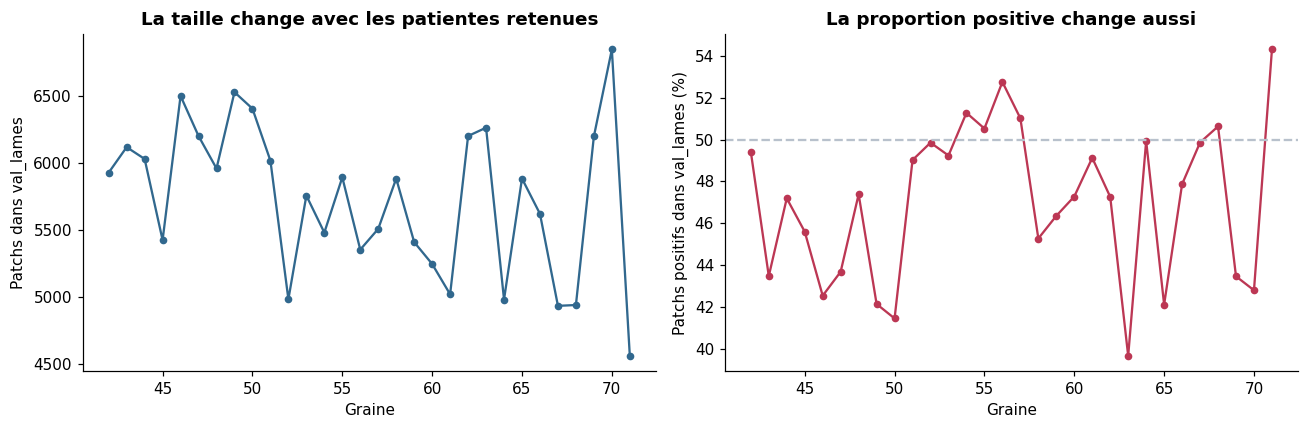

Validation de 4563 à 6847 patchs.
Part positive de 39.66 % à 54.31 %.
Aucun partage de patiente dans les 30 simulations. Toutes les bornes sont respectées.


In [8]:
def choisir_patientes(d, rng, mini=.1, maxi=.4):
    total = d.groupby("label").size()
    for essai in range(1, 1001):
        choix = []
        for p in rng.permutation(d.patient.unique()):
            choix.append(p)
            part = d.loc[d.patient.isin(choix)].groupby("label").size().reindex(total.index, fill_value=0) / total
            if part.ge(mini).all():
                break
        if part.between(mini, maxi).all():
            return choix, essai
    raise ValueError("Aucun tirage ne respecte les bornes après 1 000 essais.")

base_entr = ech.loc[ech.center.isin([0, 3, 4])].sort_values("image_id").copy()
GRAINES_DECOUPAGE = list(range(42, 72))
simulations, details = [], []
for graine in GRAINES_DECOUPAGE:
    rng = np.random.default_rng(graine)
    choisies = []
    for h in [0, 3, 4]:
        d = base_entr.loc[base_entr.center.eq(h)]
        choix, essais = choisir_patientes(d, rng)
        choisies.extend(choix)
        v = d.loc[d.patient.isin(choix)]
        for label in [0, 1]:
            part = v.label.eq(label).sum() / d.label.eq(label).sum()
            details.append({"graine": graine, "center": h, "label": label,
                "fraction_validation": part, "essais": essais})
            assert .1 <= part <= .4
    val = base_entr.loc[base_entr.patient.isin(choisies)]
    entr = base_entr.loc[~base_entr.patient.isin(choisies)]
    assert not set(val.patient) & set(entr.patient)
    assert not set(val.slide) & set(entr.slide)
    assert not set(val.image_id) & set(entr.image_id)
    assert len(val) + len(entr) == len(base_entr)
    simulations.append({"graine": graine, "patientes_validation": val.patient.nunique(),
        "lames_validation": val.slide.nunique(), "patchs_validation": len(val),
        "part_validation_pct": 100 * len(val) / len(base_entr),
        "part_positive_pct": 100 * val.label.mean(),
        "positifs_itc": int(val.loc[val.classe_lame.eq("itc"), "label"].sum()),
        "chevauchement_patientes": len(set(val.patient) & set(entr.patient))})
simulations = pd.DataFrame(simulations)
details = pd.DataFrame(details)
tableau("12_sensibilite_decoupage", simulations)
tableau("13_bornes_decoupage", details)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(simulations.graine, simulations.patchs_validation, "o-", color=BLEU, markersize=4)
axes[0].set_ylabel("Patchs dans val_lames")
axes[0].set_title("La taille change avec les patientes retenues")
axes[1].plot(simulations.graine, simulations.part_positive_pct, "o-", color=ROUGE, markersize=4)
axes[1].axhline(50, color=GRIS, ls="--")
axes[1].set_ylabel("Patchs positifs dans val_lames (%)")
axes[1].set_title("La proportion positive change aussi")
for ax in axes:
    ax.set_xlabel("Graine")
figure("05_sensibilite_decoupage", fig)

print(f"Validation de {simulations.patchs_validation.min()} à {simulations.patchs_validation.max()} patchs.")
print(f"Part positive de {simulations.part_positive_pct.min():.2f} % à {simulations.part_positive_pct.max():.2f} %.")
print(f"Aucun partage de patiente dans les {len(simulations)} simulations. Toutes les bornes sont respectées.")


Cette variation vient du nombre limité de patientes et de leurs volumes différents. Elle ne mesure pas une variation de performance du modèle. L'expérience confirme l'intérêt de documenter le découpage et les effectifs, sans chercher une graine avantageuse.


## 7. Ce que les lames disponibles permettent de dire sur pN

Je cherche à savoir si les lames disponibles suffisent à déterminer le stade pN d'une patiente. Pour isoler le manque d'information, j'utilise leurs classes officielles comme si elles étaient parfaitement connues.

Pour chaque patiente couverte hors H2, je conserve uniquement les classes des lames présentes dans les métadonnées. Je donne ensuite chaque classe possible aux lames manquantes. Les règles utilisées sont celles du [sujet du projet, page 3](https://github.com/Cloud-io09/model-cancer-sein/blob/33da9766857e51de006af6d1442739011a718dad/docs/01_Sujet_SPE1_histopathologie.pdf).

Ce calcul décrit les stades encore compatibles avec les informations disponibles. Il ne produit pas une prédiction ni une probabilité clinique.


,patient,center,lames_officielles,lames_disponibles
0,0,0,5,0
6,1,0,5,0
12,2,0,5,0
18,3,0,5,0
24,4,0,5,1
...,...,...,...,...
570,95,4,5,0
576,96,4,5,1
582,97,4,5,0
588,98,4,5,0


,patient,lames_connues,lames_manquantes,stades_compatibles,nombre_stades_possibles,pn_officiel,officiel_compatible
0,4,1,4,"pN0(i+), pN1mi, pN1, pN2",4,pN0(i+),True
1,9,1,4,"pN1mi, pN1, pN2",3,pN1mi,True
2,10,1,4,"pN1mi, pN1, pN2",3,pN1mi,True
3,12,1,4,"pN1, pN2",2,pN1,True
4,15,2,3,"pN1, pN2",2,pN1,True
5,16,1,4,"pN0(i+), pN1mi, pN1, pN2",4,pN1,True
6,17,3,2,"pN1, pN2",2,pN1,True
7,20,2,3,"pN1, pN2",2,pN1,True
8,21,1,4,"pN1mi, pN1, pN2",3,pN2,True
9,22,1,4,"pN1, pN2",2,pN1,True


,stades_compatibles,patientes
0,"pN0(i+), pN1mi, pN1",2
1,"pN0(i+), pN1mi, pN1, pN2",9
2,"pN1, pN2",12
3,"pN1mi, pN1, pN2",11


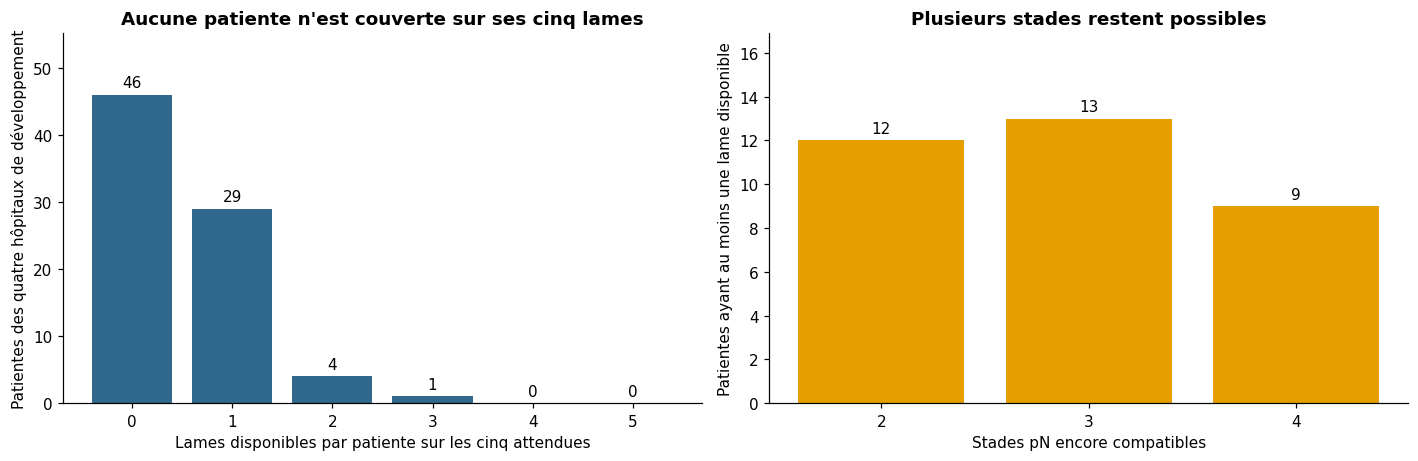

In [9]:
def stade_pn(classes):
    classes = list(classes)
    macro = classes.count("macro")
    micro = classes.count("micro")
    itc = classes.count("itc")
    atteints = macro + micro
    if atteints == 0:
        return "pN0(i+)" if itc else "pN0"
    if macro == 0:
        return "pN1mi"
    return "pN1" if atteints <= 3 else "pN2"

ORDRE_PN = ["pN0", "pN0(i+)", "pN1mi", "pN1", "pN2"]
CLASSES = ["negative", "itc", "micro", "macro"]
connues = meta[["patient", "node", "classe_lame"]].drop_duplicates()
attendues = lames_off.groupby("patient").size()
couverture = pat_off[["patient", "center"]].copy()
couverture["lames_officielles"] = couverture.patient.map(attendues)
couverture["lames_disponibles"] = couverture.patient.map(connues.groupby("patient").size()).fillna(0).astype(int)
tableau("14_couverture_patientes", couverture)

possibles = []
for p, g in connues.groupby("patient"):
    n_manquantes = int(attendues.loc[p] - len(g))
    stades_possibles = {stade_pn(g.classe_lame.tolist() + list(suite))
        for suite in product(CLASSES, repeat=n_manquantes)}
    possibles.append({"patient": int(p), "lames_connues": len(g), "lames_manquantes": n_manquantes,
        "stades_compatibles": ", ".join(s for s in ORDRE_PN if s in stades_possibles),
        "nombre_stades_possibles": len(stades_possibles)})
incertitude = pd.DataFrame(possibles)

# Le stade officiel est ajouté seulement après l'énumération.
incertitude = incertitude.merge(pat_off[["patient", "pn_officiel"]], on="patient", validate="one_to_one")
incertitude["officiel_compatible"] = incertitude.apply(
    lambda r: r.pn_officiel in r.stades_compatibles.split(", "), axis=1)
assert incertitude.officiel_compatible.all()
tableau("15_incertitude_pn", incertitude)
groupes_pn = incertitude.groupby("stades_compatibles", as_index=False).agg(patientes=("patient", "size"))
tableau("16_stades_compatibles", groupes_pn)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
compte = couverture.lames_disponibles.value_counts().reindex(range(6), fill_value=0)
bars = axes[0].bar(compte.index.astype(str), compte.values, color=BLEU)
axes[0].bar_label(bars, padding=3)
axes[0].set_ylim(0, compte.max() * 1.2)
axes[0].set_xlabel("Lames disponibles par patiente sur les cinq attendues")
axes[0].set_ylabel("Patientes des quatre hôpitaux de développement")
axes[0].set_title("Aucune patiente n'est couverte sur ses cinq lames")
n_possibles = incertitude.nombre_stades_possibles.value_counts().sort_index()
bars = axes[1].bar(n_possibles.index.astype(str), n_possibles.values, color=ORANGE)
axes[1].bar_label(bars, padding=3)
axes[1].set_ylim(0, n_possibles.max() * 1.3)
axes[1].set_xlabel("Stades pN encore compatibles")
axes[1].set_ylabel("Patientes ayant au moins une lame disponible")
axes[1].set_title("Plusieurs stades restent possibles")
figure("06_couverture_pn", fig)


Cette vérification utilise des classes de lames parfaites pour isoler le manque d'information. Elle n'utilise pas les vraies classes des lames absentes pour réduire les possibilités. Les possibilités ne reçoivent aucune probabilité.

Le résultat pN du notebook principal mesure l'effet de remplacer certaines classes de lames, les autres gardant leur vérité officielle. Il faut le présenter comme une évaluation partielle. Les images disponibles ne permettent pas de mesurer ici un système autonome couvrant toutes les lames d'une patiente.


## 8. Synthèse

Les constats suivants sont calculés à partir des cellules précédentes. Ils portent tous sur H0, H1, H3 et H4.


In [10]:
part_macro = types.loc["macro", "part_positifs_retenus_pct"]
top2 = 100 * patientes.patchs_retenus.head(2).sum() / len(ech)
moy_lame = moyennes.loc[moyennes.ensemble.eq("Retenu") & moyennes.meme_poids_par.eq("Lame"), "part_positive_pct"].iloc[0]
identifiables = int(incertitude.nombre_stades_possibles.eq(1).sum())

CONSTATS = [
    f"Les {nombre(len(ech))} patchs retenus couvrent les mêmes {ech.slide.nunique()} lames et {ech.patient.nunique()} patientes que les métadonnées de développement.",
    f"Le sous-échantillon est équilibré entre les deux labels, mais {part_macro:.2f} % de ses positifs viennent de lames macro.",
    f"{len(perdues)} lames itc perdent tous leurs positifs disponibles. H1 ne conserve que {n_itc_h1} positifs issus de lames itc.",
    f"Les deux patientes les plus représentées fournissent {top2:.2f} % des patchs. La moyenne des proportions positives par lame est de {moy_lame:.2f} %, contre {100 * ech.label.mean():.0f} % pour la moyenne par patch.",
    f"Sur les {len(simulations)} graines, la validation comporte de {simulations.patchs_validation.min()} à {simulations.patchs_validation.max()} patchs, sans patiente partagée avec l'entraînement.",
    f"Avec les seules classes parfaites des lames disponibles, {identifiables} patiente sur {len(incertitude)} a un stade pN complètement déterminé."
]
for i, phrase in enumerate(CONSTATS, start=1):
    print(f"{i}. {phrase}")

manifest = {
    "commit_source": BASE_COMMIT,
    "centres_analyses": CENTRES,
    "graines_decoupage": GRAINES_DECOUPAGE,
    "python": sys.version.split()[0],
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "sha256": {nom: hashlib.sha256((DATA / nom).read_bytes()).hexdigest() for nom in FICHIERS},
    "constats": CONSTATS
}
if EXPORTER:
    (SORTIE / "reproductibilite.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
    texte = "# Exploration complémentaire\n\n" + "\n\n".join(CONSTATS)
    texte += "\n\nLes calculs excluent H2. Aucun modèle n'a été entraîné et aucune performance de prédiction n'a été mesurée.\n"
    texte += "\nLes données viennent des trois fichiers du dossier data. Les références sont le sujet fourni, pages 2 à 5, Koh et al. (2021), https://proceedings.mlr.press/v139/koh21a.html, et Bándi et al. (2019), https://doi.org/10.1109/TMI.2018.2867350. Les références donnent le contexte, les nouveaux résultats viennent des calculs de ce notebook.\n"
    texte += "\nDans le cadre du projet, j'ai mené mes recherches et utilisé le modèle. ChatGPT m'a aidé à formuler et à organiser les explications présentées dans ce notebook.\n"
    (SORTIE / "README.md").write_text(texte, encoding="utf-8")


1. Les 31 000 patchs retenus couvrent les mêmes 40 lames et 34 patientes que les métadonnées de développement.
2. Le sous-échantillon est équilibré entre les deux labels, mais 96.02 % de ses positifs viennent de lames macro.
3. 3 lames itc perdent tous leurs positifs disponibles. H1 ne conserve que 3 positifs issus de lames itc.
4. Les deux patientes les plus représentées fournissent 25.17 % des patchs. La moyenne des proportions positives par lame est de 25.47 %, contre 50 % pour la moyenne par patch.
5. Sur les 30 graines, la validation comporte de 4563 à 6847 patchs, sans patiente partagée avec l'entraînement.
6. Avec les seules classes parfaites des lames disponibles, 0 patiente sur 34 a un stade pN complètement déterminé.


## Ce que je retiens

Les données sont équilibrées entre patchs normaux et tumoraux, mais les petites lésions restent peu représentées. Certaines patientes pèsent beaucoup plus que d'autres dans les moyennes. Le découpage par patiente évite leur présence dans les deux ensembles, mais la composition de la validation varie selon la graine.

Les lames disponibles ne suffisent pas à fixer un stade pN unique pour les patientes étudiées. Je dois donc distinguer les résultats sur les patchs, ceux sur les lames et ceux qui utilisent encore des classes officielles de ganglions absents des images.

Cette exploration complète le travail du groupe en précisant les limites des données. Les chiffres viennent de l'exécution des cellules de ce notebook.

## Sources

1. Koh et al. (2021). [WILDS, A Benchmark of in-the-Wild Distribution Shifts](https://proceedings.mlr.press/v139/koh21a.html). ICML, PMLR 139, pages 5637 à 5664. Référence pour les différences entre domaines et hôpitaux.
2. Bándi et al. (2019). [From Detection of Individual Metastases to Classification of Lymph Node Status at the Patient Level, The CAMELYON17 Challenge](https://doi.org/10.1109/TMI.2018.2867350). IEEE Transactions on Medical Imaging, 38(2), pages 550 à 560. Référence pour le cadre CAMELYON17.
3. [Sujet SPÉ 1](https://github.com/Cloud-io09/model-cancer-sein/blob/33da9766857e51de006af6d1442739011a718dad/docs/01_Sujet_SPE1_histopathologie.pdf), pages 2 à 5. Périmètre des données, règles pN et séparation des ensembles.
4. [Notebook du groupe](https://github.com/Cloud-io09/model-cancer-sein/blob/33da9766857e51de006af6d1442739011a718dad/SPE1_notebook_demarrage.ipynb), section sur le découpage par patiente. Règle utilisée pour l'expérience sur les 30 graines.

Les données utilisées sont `metadata_complete.zip`, `ids_sous_echantillon.csv` et `stages.csv`, dans le dossier `data` du commit `33da9766857e51de006af6d1442739011a718dad` de `version-finale`. Les références scientifiques donnent le contexte. Elles ne sont pas la source des nouveaux résultats calculés ici.

## Aide de ChatGPT

Dans le cadre du projet, j'ai mené mes recherches et utilisé le modèle. ChatGPT m'a aidé à formuler et à organiser les explications présentées dans ce notebook.


In [ ]:
from google.colab import files
from pathlib import Path
from getpass import getpass
import subprocess
import tempfile
import base64
import os

branche = "exploration-complementaire"
nom = "SPE1_exploration_complementaire (ERIC MOIS).ipynb"
repo = "https://github.com/Cloud-io09/model-cancer-sein.git"

uploaded = files.upload()
contenu = uploaded[nom]

token = getpass("Token GitHub : ")
email = input("Email GitHub : ")

env = os.environ.copy()
auth = base64.b64encode(f"x-access-token:{token}".encode()).decode()
env["GIT_CONFIG_COUNT"] = "1"
env["GIT_CONFIG_KEY_0"] = "http.extraHeader"
env["GIT_CONFIG_VALUE_0"] = f"Authorization: Basic {auth}"

dossier = Path(tempfile.mkdtemp()) / "model-cancer-sein"

subprocess.run(
    ["git", "clone", repo, str(dossier)],
    env=env, check=True
)

def git(*args):
    return subprocess.run(
        ["git", "-C", str(dossier), *args],
        env=env, check=True, capture_output=True, text=True
    ).stdout

if git("branch", "-r", "--list", f"origin/{branche}").strip():
    git("switch", "-c", branche, f"origin/{branche}")
else:
    git("switch", "-c", branche, "origin/version-finale")

git("config", "user.name", "ERIC MOIS")
git("config", "user.email", email)

(dossier / nom).write_bytes(contenu)

git("add", "--", nom)

if git("diff", "--cached", "--name-only").strip():
    git("commit", "-m", "Ajout de mon exploration complementaire")

git("push", "-u", "origin", branche)

print("Notebook publié sur GitHub")
print(f"https://github.com/Cloud-io09/model-cancer-sein/tree/{branche}")